In [1]:
import numpy as np
import matplotlib.pyplot as plt

from core.bipartite_calc import (compute_coarse_phase_diagram, extract_configuration_bank,
                                 compute_fine_phase_diagram, classify_phase_diagram, select_phases,
                                 refine_phase_diagram)
from core.bipartite_plot import plot_figure_bipartite

# Figure 5

Complete bipartite network $K_{4,4}$. A coarse scan collects candidate configurations, which are reduced to one representative per support class. The fine scan then starts from every representative at every point and keeps the lowest dissipation.

In [2]:
Ng, Nc = 4, 4
mu = 1.0
beta_star = (Nc / Ng) * mu

coarse_beta = np.logspace(-1.5, 1.5, 50) * beta_star
coarse_gamma = np.linspace(0.10, 1.05, 50)

coarse_path = "scan_data/coarse_results_K44_mu1_seed0.npz"

try:
    coarse_results = dict(np.load(coarse_path))
except FileNotFoundError:
    coarse_results = compute_coarse_phase_diagram(Ng, Nc, mu, coarse_beta, coarse_gamma, seed=0)
    np.savez_compressed(coarse_path, **coarse_results)

One representative configuration per support class

In [3]:
bank = extract_configuration_bank(coarse_results, Ng, Nc)
print(f"bank: {len(bank)} distinct configurations")

bank: 35 distinct configurations


Fine scan: every point tries every configuration of the bank

In [5]:
fine_beta = np.logspace(-1.5, 1.5, 200) * beta_star
fine_gamma = np.linspace(0.10, 1.05, 200)

fine_path = "scan_data/fine_results_K44_mu1_seed0.npz"

try:
    fine_results = dict(np.load(fine_path))
except FileNotFoundError:
    fine_results = compute_fine_phase_diagram(Ng, Nc, mu, fine_beta, fine_gamma, bank)
    np.savez_compressed(fine_path, **fine_results)

  beta 200/200


Final figure

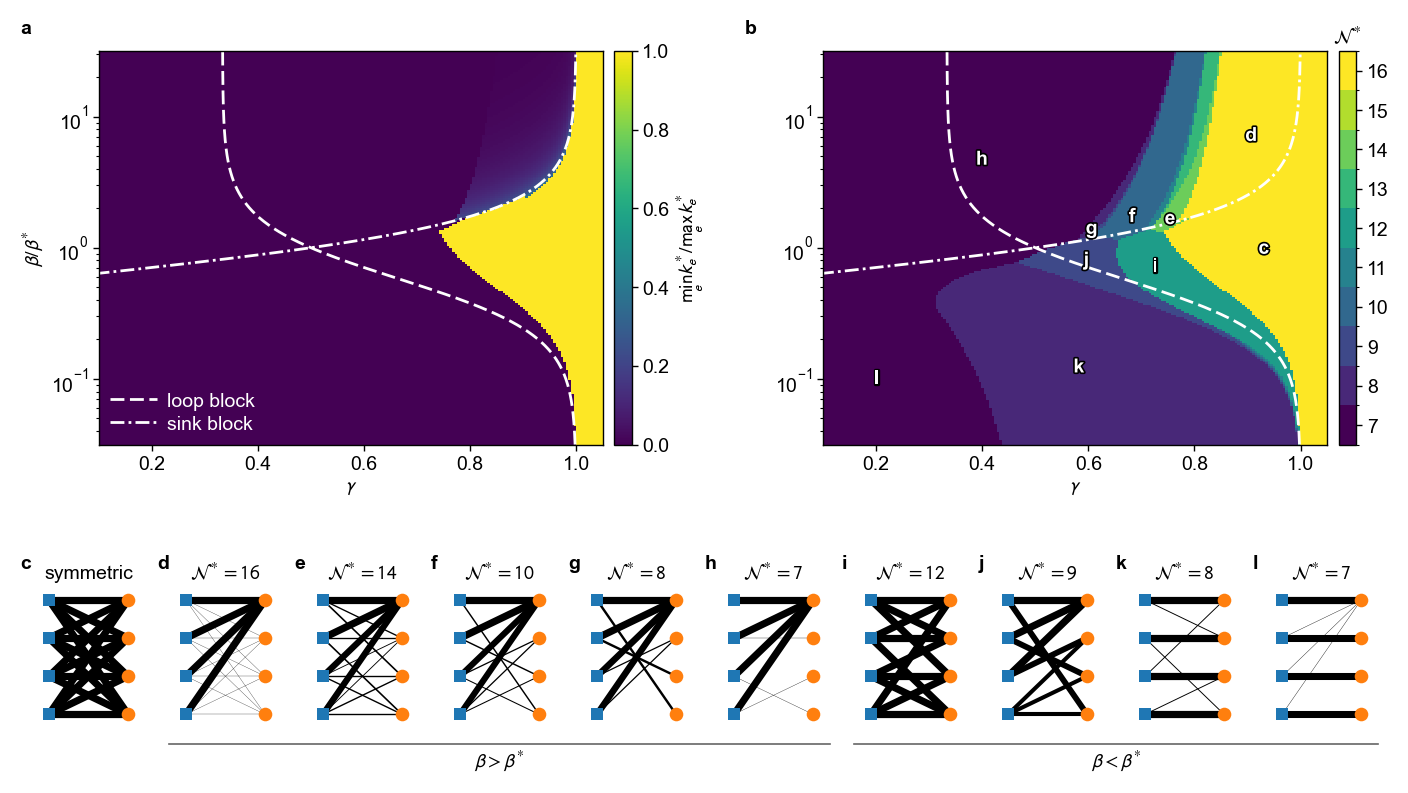

In [9]:
labels = classify_phase_diagram(fine_results, Ng, Nc)

# gallery: the largest classes, without the 13-edge configuration (label 5),
# which differs from its neighbours by single weak edges
gallery, n_strong = select_phases(fine_results, labels, beta_star, n_show=10, skip=[5])

# the tree again, at weak noise: same phase as at strong noise, opposite capacity pattern
ib = np.argmin(np.abs(fine_results["beta_values"] / beta_star - 0.1))
ig = np.argmin(np.abs(fine_results["gamma_values"] - 0.2))
gallery.append(dict(label=int(labels[ib, ig]), symmetric=False, fraction=0.0,
                    n_edges=int(fine_results["n_active"][ib, ig]), k=fine_results["k"][ib, ig],
                    beta=float(fine_results["beta_values"][ib]), gamma=float(fine_results["gamma_values"][ig])))

fig, info = plot_figure_bipartite(fine_results, gallery, n_strong, Ng, Nc, mu,
                                  labels=labels, letter_offset={"h": (7, 0)},
                                  savepath="Figure5.pdf")
plt.show()

All phases

In [7]:
cls, counts = np.unique(labels, return_counts=True)
for c, n in sorted(zip(cls, counts), key=lambda t: -t[1]):
    ib, ig = np.argwhere(labels == c)[0]
    name = "symmetric" if c == -1 else f"N*={fine_results['n_active'][ib, ig]}"
    print(f"{c:3d}  {name:10s}  {100 * n / labels.size:5.2f} % of the plane")

  0  N*=7        45.95 % of the plane
  1  N*=8        22.55 % of the plane
 -1  symmetric   12.64 % of the plane
 13  N*=16        6.40 % of the plane
  7  N*=12        4.02 % of the plane
  4  N*=10        3.39 % of the plane
  2  N*=9         2.35 % of the plane
  5  N*=13        0.88 % of the plane
  8  N*=14        0.76 % of the plane
  9  N*=8         0.52 % of the plane
 12  N*=11        0.15 % of the plane
 11  N*=11        0.15 % of the plane
  6  N*=9         0.11 % of the plane
  3  N*=10        0.07 % of the plane
 10  N*=11        0.07 % of the plane


For caption

In [8]:
for letter, n_edges, g, b in info:  # for the caption
    print(f"{letter}: N*={n_edges}, gamma={g:.2f}, beta/beta*={b / beta_star:.2f}")

c: N*=16, gamma=0.93, beta/beta*=0.98
d: N*=16, gamma=0.91, beta/beta*=7.11
e: N*=14, gamma=0.75, beta/beta*=1.65
f: N*=10, gamma=0.68, beta/beta*=1.71
g: N*=8, gamma=0.61, beta/beta*=1.39
h: N*=7, gamma=0.36, beta/beta*=4.69
i: N*=12, gamma=0.73, beta/beta*=0.72
j: N*=9, gamma=0.60, beta/beta*=0.80
k: N*=8, gamma=0.58, beta/beta*=0.12
l: N*=7, gamma=0.20, beta/beta*=0.10
